# Policy2Agreement: the running example with federated learning and differential privacy

This notebook reproduces the proof of concept of the paper (Section 4 and Table 1). It first negotiates the agreements of Table 1, and then **executes** them: two hospitals train a diagnostic model with federated averaging, each protecting its patients with differential privacy. In the negotiation, the privacy budget $\varepsilon$, the F1 score $q$ and the number of rounds $t$ are positions in a grid; here, $\varepsilon$ is the budget of DP-SGD, $t$ the number of federated rounds and $q$ the F1 score the trained model must reach.

| Part | What it does |
|---|---|
| 1 | The running example: the parties' norms and the domain rule |
| 2 | Phases 2 to 4: the agreements of Table 1, checked against the prototype's recorded results, and the other claims of Sections 3 and 4 on the negotiation |
| 3 | Federated learning with differential privacy: DP-SGD at each hospital, FedAvg at the orchestrator, an RDP accountant |
| 4 | Which $(\varepsilon, t)$ can reach which F1 score |
| 5 | The domain rule against the data |
| 6 | Executing the agreements (the "F1 met" column of Table 1), with 95% intervals |
| 7 | The recorded language-model rule proposals of Section 4 (not re-run: they need an API key) |

Run it from this folder after `pip install -r requirements.txt` (see `README.md`). It needs no network access and takes a few minutes; results are written to `results/fl_dp_results.json`.

In [1]:
import itertools, json, multiprocessing as mp, os, sys, time
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")       # small matrices: one BLAS thread per process is fastest
from collections import Counter
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gammaln, logsumexp
from sklearn.model_selection import StratifiedKFold, train_test_split

HERE = Path.cwd()
assert (HERE / "p2a_negotiation.py").exists(), "run this notebook from the folder that contains it"
RESULTS, DATA = HERE / "results", HERE / "data"
RESULTS.mkdir(exist_ok=True)

import p2a_negotiation as p2a      # Phases 2 to 4: domain rule, compiler of Eq. (1), MiCRO-Min under SAOP

pd.set_option("display.width", 200, "display.max_colwidth", 60)
T0 = time.time()

## 1. The running example

Each party's norms are permissions qualified by constraints $\langle j, \diamond, v\rangle$ on the issues $\varepsilon$, $q$ and $t$. In the paper's prototype they are written in [ODRL](https://www.w3.org/TR/odrl-model/), the W3C policy language that data spaces use; here they are the same constraints as Python data. In the variant of Section 4, $R$ requires $t \ge 15$ instead of $t \le 20$. Two authorities govern the parties: a consortium obliges $t \ge 15$ and a regulator forbids $\varepsilon > 0.6$. As in the paper's Table 1, the negotiations below apply the consortium's obligation but not the regulator's prohibition, which the prototype does not yet handle.

In [2]:
pd.DataFrame([dict(party=p, constraints=", ".join(f"{j} {'<=' if op == 'lteq' else '>='} {v}" for j, op, v in cs),
                   variant=", ".join(f"{j} {'<=' if op == 'lteq' else '>='} {v}" for j, op, v in p2a.VARIANT[p]))
              for p, cs in p2a.RUNNING_EXAMPLE.items()]).set_index("party")

,constraints,variant
party,,
H1,"eps <= 0.3, q >= 0.92","eps <= 0.3, q >= 0.92"
H2,"eps <= 0.5, t <= 15","eps <= 0.5, t <= 15"
R,"q >= 0.85, t <= 20","q >= 0.85, t >= 15"


The domain rule flags a party that asks for both $q \ge 0.92$ and $\varepsilon \le 0.3$, with a multiplier $\mu$: a high F1 score under a strict privacy budget is implausible, not impossible. In the prototype it is an N3 rule executed by the EYE reasoner, which a language-model agent can draft and which enters the rulebook only once the governance authority approves it; `p2a.domain_rule` encodes the same pattern. It fires for $H_1$ only:

In [3]:
{p: [cs[i] for i in p2a.domain_rule(cs)] for p, cs in p2a.RUNNING_EXAMPLE.items()}

{'H1': [('eps', 'lteq', 0.3), ('q', 'gteq', 0.92)], 'H2': [], 'R': []}

The prototype reads these norms from ODRL policies (`data/odrl/`): each party states constraints on its own data in an Offer and on the shared model in a Request. The notebook does not parse them, but the next cell checks that the constraints above are exactly the ones in those files.

In [4]:
import re
OPERAND = {"epsilon": "eps", "f1Score": "q", "rounds": "t"}
def odrl_constraints(*files):
    found = []
    for f in files:
        text = (DATA / "odrl" / f).read_text()
        for operand, op, value in re.findall(r'leftOperand fl:(\w+) ;\s*odrl:operator odrl:(\w+) ;\s*odrl:rightOperand "([\d.]+)"', text):
            found.append((OPERAND[operand], op, float(value) if "." in value else int(value)))
    return sorted(found)

assert odrl_constraints("h1_offer.ttl", "h1_request.ttl") == sorted(p2a.RUNNING_EXAMPLE["H1"])
assert odrl_constraints("h2_offer.ttl", "h2_request.ttl") == sorted(p2a.RUNNING_EXAMPLE["H2"])
assert odrl_constraints("r_request.ttl") == sorted(p2a.RUNNING_EXAMPLE["R"])
assert odrl_constraints("r_request_variant.ttl") == sorted(p2a.VARIANT["R"])
print("the constraints match the ODRL policies in data/odrl/")
print((DATA / "odrl" / "h1_offer.ttl").read_text())

the constraints match the ODRL policies in data/odrl/
@prefix odrl: <http://www.w3.org/ns/odrl/2/> .
@prefix fl:   <http://example.com/fl-policies#> .
@prefix xsd:  <http://www.w3.org/2001/XMLSchema#> .

<http://example.com/policies/h1-offer>
  a odrl:Offer ;
  odrl:assigner <http://example.com/parties/H1> ;
  fl:pairedWith <http://example.com/policies/h1-request> ;
  odrl:permission [
    a odrl:Permission ;
    odrl:action odrl:use ;
    odrl:target <http://example.com/assets/H1-data> ;
    odrl:constraint
      [ a odrl:Constraint ;
        odrl:leftOperand fl:epsilon ;
        odrl:operator odrl:lteq ;
        odrl:rightOperand "0.3"^^xsd:decimal ;
        fl:priority 1 ]
  ] .



## 2. Negotiating the agreements (Phases 2 to 4)

Each setting is compiled (Phase 2: the feasible set $\Omega_F$ and the domain rule; Phase 3: the utilities of Eq. (1) and the adjusted utilities $\hat u_i$) and negotiated with MiCRO-Min under SAOP (Phase 4) for 6 turn orders $\times$ 20 seeds, exactly as for Table 1 of the paper. The consortium's obligation $t \ge 15$ prunes $\Omega_F$; in the variant, $R$ requires $t \ge 15$ instead of $t \le 20$. The table lists each agreement with each party's adjusted utility $\hat u_i$ and the mean number of steps.

`p2a_negotiation.py` ports the prototype's compiler and negotiation engine to plain Python, without the reasoner. The next cell checks that it reproduces the agreements and step counts the prototype recorded.

In [5]:
SETTINGS = [  # label, parties, compile options, H1 states that privacy comes first
    ("no domain rule",         p2a.RUNNING_EXAMPLE, dict(mu=0.2, raw=True), False),
    ("rule, mu = 0.2",         p2a.RUNNING_EXAMPLE, dict(mu=0.2), False),
    ("rule, mu = 0.5",         p2a.RUNNING_EXAMPLE, dict(mu=0.5), False),
    ("rule, mu = 0.8",         p2a.RUNNING_EXAMPLE, dict(mu=0.8), False),
    ("rule, mu = 0.9",         p2a.RUNNING_EXAMPLE, dict(mu=0.9), False),
    ("+ consortium's t >= 15", p2a.RUNNING_EXAMPLE, dict(mu=0.2, omega_filter=p2a.consortium_obligation), False),
    ("+ H1: privacy first",    p2a.RUNNING_EXAMPLE, dict(mu=0.2, omega_filter=p2a.consortium_obligation), True),
    ("variant, no rule",       p2a.VARIANT,         dict(mu=0.2, raw=True), False),
    ("variant, mu = 0.2",      p2a.VARIANT,         dict(mu=0.2), False),
]

nego, rows = {}, []
for label, parties, kw, prio in SETTINGS:
    problem = p2a.compile_problem(parties, **kw)
    r = p2a.negotiate_all(p2a.privacy_first(problem) if prio else problem)
    nego[label] = dict(omega_f=len(problem["omega_f"]), dist=r["agreements"], steps=r["mean_steps"], deadlocks=r["deadlocks"])
    for omega, n in sorted(r["agreements"].items(), key=lambda kv: -kv[1]):
        rows.append(dict(setting=label, omega_f=len(problem["omega_f"]), agreement=str(omega), runs=f"{n}/120", _omega=omega,
                         **{f"u_{a}": round(p2a.utility_at(problem, a, omega)[1], 2) for a in ("H1", "H2", "R")},
                         steps=round(r["mean_steps"], 1)))
table_nego = pd.DataFrame(rows)
print(f"negotiations done in {time.time() - T0:.0f} s; deadlocks: {sum(v['deadlocks'] for v in nego.values())}")
table_nego.drop(columns="_omega")

negotiations done in 1 s; deadlocks: 0


,setting,omega_f,agreement,runs,u_H1,u_H2,u_R,steps
0,no domain rule,48,"(0.3, 0.92, 10)",120/120,1.00,1.00,1.00,2.3
1,"rule, mu = 0.2",48,"(0.5, 0.92, 10)",120/120,0.83,0.83,1.00,17.8
2,"rule, mu = 0.5",48,"(0.5, 0.92, 10)",120/120,0.83,0.83,1.00,17.8
3,"rule, mu = 0.8",48,"(0.5, 0.92, 10)",120/120,0.83,0.83,1.00,17.8
4,"rule, mu = 0.9",48,"(0.3, 0.92, 10)",120/120,0.90,1.00,1.00,2.3
5,+ consortium's t >= 15,32,"(0.3, 0.9, 15)",60/120,0.83,0.75,0.58,18.3
6,+ consortium's t >= 15,32,"(0.5, 0.92, 15)",60/120,0.83,0.58,0.75,18.3
7,+ H1: privacy first,32,"(0.3, 0.9, 15)",120/120,0.83,0.75,0.58,20.3
8,"variant, no rule",48,"(0.3, 0.92, 15)",120/120,1.00,0.75,0.75,34.1
9,"variant, mu = 0.2",48,"(0.5, 0.92, 15)",120/120,0.83,0.58,0.75,57.2


In [6]:
# The same agreements and mean step counts as the paper's prototype recorded for Table 1 (results/table1_prototype.json)
recorded = json.loads((RESULTS / "table1_prototype.json").read_text())["settings"]
for label in nego:
    ours = {f"({e}, {q}, {t})": n for (e, q, t), n in nego[label]["dist"].items()}
    assert ours == recorded[label]["agreements"], (label, ours, recorded[label]["agreements"])
    assert abs(nego[label]["steps"] - recorded[label]["mean_steps"]) < 1e-9, (label, nego[label]["steps"])
print("all agreements and step counts match results/table1_prototype.json")

# ... and the same inputs: the adjusted utilities the prototype compiled and fed to MiCRO-Min (results/prototype_utilities.json)
proto = json.loads((RESULTS / "prototype_utilities.json").read_text())["settings"]
compared = 0
for label, parties, kw, prio in SETTINGS + [("rule, mu = 0.37", p2a.RUNNING_EXAMPLE, dict(mu=0.37), False)]:
    problem = p2a.compile_problem(parties, **kw)
    problem = p2a.privacy_first(problem) if prio else problem
    assert [[o["eps"], o["q"], o["t"]] for o in problem["omega_f"]] == proto[label]["omega_f"], label
    for party in problem["parties"]:
        ours = [row["u_hat"] for row in problem["utilities"][party]]
        assert ours == proto[label]["u_hat"][party], (label, party)     # exact equality, not a tolerance
        compared += len(ours)
print(f"all {compared} compiled utilities equal the prototype's, in {len(proto)} settings")

all agreements and step counts match results/table1_prototype.json
all 1344 compiled utilities equal the prototype's, in 10 settings


### Other claims on the negotiation

Three more claims of the paper follow from the same compiled problems. In Section 3, the rule drops $H_1$'s stated ideal from first to 37th of the 48 outcomes, and its two next-best options rise to joint first. In Section 4, every $\mu$ below $5/6$ yields $\omega^\star$, while $\mu = 0.9$ does not: the agreement can change only where $\mu$ times the favorite's utility crosses $H_1$'s next-best utility, $5/6$. And by Table 1's caption, every agreement is Pareto-optimal over $\Omega_F$, with respect to the adjusted utilities $\hat u_i$ the agents negotiate with.

The cell also checks two things the paper states in passing: every agreement lies inside every party's acceptance set (Phase 4; the engine, like the prototype's, uses a reservation value of 0, so this is checked rather than enforced), and the seeds change only the step counts, never the agreement, so where agreements differ, the turn order is the cause.

In [7]:
def rank(problem, party, outcome):              # 1 + the number of strictly better outcomes
    me = p2a.utility_at(problem, party, outcome)[1]
    return 1 + sum(row["u_hat"] > me + 1e-12 for row in problem["utilities"][party])

favorite = (0.3, 0.92, 10)
raw = p2a.compile_problem(p2a.RUNNING_EXAMPLE, mu=0.2, raw=True)
rule = p2a.compile_problem(p2a.RUNNING_EXAMPLE, mu=0.2)
top = max(row["u_hat"] for row in rule["utilities"]["H1"])
joint_first = sorted({(o["eps"], o["q"]) for o, row in zip(rule["omega_f"], rule["utilities"]["H1"]) if abs(row["u_hat"] - top) < 1e-12})
print(f"H1's stated ideal {favorite}: rank {rank(raw, 'H1', favorite)} without the rule, "
      f"{rank(rule, 'H1', favorite)} of {len(rule['omega_f'])} with it (u_hat = {p2a.utility_at(rule, 'H1', favorite)[1]:.2f})")
print(f"H1's joint-first options with the rule, for any t: (eps, q) in {joint_first}, u_hat = {top:.2f}")

mus = [round(0.05 * k, 2) for k in range(1, 21)] + [0.83, 0.8333]
sweep = sorted((mu, dict(p2a.negotiate_all(p2a.compile_problem(p2a.RUNNING_EXAMPLE, mu=mu))["agreements"])) for mu in mus)
print("\nagreement as mu grows (5/6 = 0.8333...):")
for i, (mu, agreements) in enumerate(sweep):
    if i == 0 or agreements != sweep[i - 1][1]:
        print(f"  from mu = {mu}: {agreements}")

def pareto_optimal(problem, outcome):            # no outcome of Omega_F is at least as good for all and better for one
    me = [p2a.utility_at(problem, p, outcome)[1] for p in problem["parties"]]
    for o in problem["omega_f"]:
        other = [p2a.utility_at(problem, p, (o["eps"], o["q"], o["t"]))[1] for p in problem["parties"]]
        if all(x >= y - 1e-12 for x, y in zip(other, me)) and any(x > y + 1e-12 for x, y in zip(other, me)):
            return False
    return True

checked = []
for label, parties, kw, prio in SETTINGS:
    problem = p2a.compile_problem(parties, **kw)
    problem = p2a.privacy_first(problem) if prio else problem
    checked += [pareto_optimal(problem, omega) for omega in nego[label]["dist"]]
print(f"\nPareto-optimal over Omega_F (adjusted utilities): {sum(checked)} of {len(checked)} agreements")
stated = [p2a.utility_at(raw, p, (0.5, 0.92, 10))[0] for p in raw["parties"]]
print(f"by the stated utilities u, the favorite (1.00, 1.00, 1.00) dominates omega* {tuple(round(x, 2) for x in stated)}: "
      "the rule discounts the favorite because it is implausible (Part 6)")

def in_acceptance_set(parties, party, outcome):  # every constraint the rule did not flag holds
    cs, flagged = parties[party], set(p2a.domain_rule(parties[party]))
    o = dict(zip(p2a.ISSUES, outcome))
    return all(p2a.holds(o, c) for k, c in enumerate(cs) if k not in flagged)

inside = [in_acceptance_set(parties, p, omega) for label, parties, kw, prio in SETTINGS
          for omega in nego[label]["dist"] for p in parties]
print(f"\nagreements inside each party's acceptance set: {sum(inside)} of {len(inside)} (agreement, party) pairs")

by_order = {}
for label, parties, kw, prio in SETTINGS:
    problem = p2a.compile_problem(parties, **kw)
    problem = p2a.privacy_first(problem) if prio else problem
    for order in itertools.permutations(problem["parties"]):
        found = {tuple(p2a.negotiate(problem, order, seed)[0].values()) for seed in range(20)}
        assert len(found) == 1, (label, order, found)                   # the seed never changes the agreement
        by_order[(label, "-".join(order))] = found.pop()
print("in every setting and turn order, all 20 seeds reach the same agreement")
CONSORTIUM = "+ consortium's t >= 15"
print(f"\n{CONSORTIUM}, agreement by turn order:")
for order in itertools.permutations(("H1", "H2", "R")):
    print(f"  {'-'.join(order)}: {by_order[(CONSORTIUM, '-'.join(order))]}")

H1's stated ideal (0.3, 0.92, 10): rank 1 without the rule, 37 of 48 with it (u_hat = 0.20)
H1's joint-first options with the rule, for any t: (eps, q) in [(0.3, 0.9), (0.5, 0.92)], u_hat = 0.83



agreement as mu grows (5/6 = 0.8333...):
  from mu = 0.05: {(0.5, 0.92, 10): 120}
  from mu = 0.85: {(0.3, 0.92, 10): 120}

Pareto-optimal over Omega_F (adjusted utilities): 10 of 10 agreements
by the stated utilities u, the favorite (1.00, 1.00, 1.00) dominates omega* (0.83, 0.83, 1.0): the rule discounts the favorite because it is implausible (Part 6)

agreements inside each party's acceptance set: 30 of 30 (agreement, party) pairs


in every setting and turn order, all 20 seeds reach the same agreement

+ consortium's t >= 15, agreement by turn order:
  H1-H2-R: (0.3, 0.9, 15)
  H1-R-H2: (0.5, 0.92, 15)
  H2-H1-R: (0.5, 0.92, 15)
  H2-R-H1: (0.3, 0.9, 15)
  R-H1-H2: (0.3, 0.9, 15)
  R-H2-H1: (0.5, 0.92, 15)


## 3. Federated learning with differential privacy

### 3.1 Data and federation

The Wisconsin breast-cancer data (original) hold 699 biopsies with nine cytology features on a 1 to 10 scale (Wolberg and Mangasarian, 1990); 241 are malignant. We rescale with the public bounds of that scale, so no statistic of the data is used before training, and fill the 16 missing values with the scale's midpoint. Each run is a 5-fold cross-validation: the four training folds are split, stratified, between $H_1$ and $H_2$ (about 280 patients each), and the orchestrator $R$ holds no data.

In [8]:
raw = pd.read_csv(DATA / "breast_w.csv")                     # OpenML 15 "breast-w", see README.md
FEATURES = list(raw.columns[:9])
X_all = raw[FEATURES].astype(float).fillna(5.5).to_numpy()   # 16 missing Bare_Nuclei -> midpoint of the 1..10 scale
X_all = (X_all - 5.5) / 4.5                                    # public 1..10 bounds -> [-1, 1]
y_all = (raw["Class"] == "malignant").to_numpy(float)          # positive class: malignant

@lru_cache(None)
def folds(seed, k=5):
    out = []
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=seed).split(X_all, y_all):
        Xtr = np.hstack([X_all[tr], np.ones((len(tr), 1))])
        Xte = np.hstack([X_all[te], np.ones((len(te), 1))])
        a, b, ya, yb = train_test_split(Xtr, y_all[tr], test_size=0.5, stratify=y_all[tr], random_state=seed + 1000)
        out.append((((a, ya), (b, yb)), (Xte, y_all[te])))     # ((H1, H2), held-out fold)
    return out

(h1, h2), test = folds(0)[0]
print(f"{len(y_all)} patients, {int(y_all.sum())} malignant; per fold: H1 {len(h1[1])}, H2 {len(h2[1])}, test {len(test[1])}")

699 patients, 241 malignant; per fold: H1 279, H2 280, test 140


### 3.2 Privacy accounting

Each hospital protects its patients with record-level $(\varepsilon, \delta)$-differential privacy, $\delta = 10^{-5}$, over the whole training. DP-SGD with Poisson sampling is a subsampled Gaussian mechanism. We compose its Rényi DP over all steps (Mironov 2017; Mironov, Talwar and Zhang 2019), convert to $(\varepsilon, \delta)$ (Canonne, Kamath and Steinke 2020), and calibrate the noise multiplier $\sigma$ to the agreed $\varepsilon$. The two checks reproduce Google's `dp-accounting` library (`RdpAccountant`, same orders) to the printed precision.

In [9]:
DELTA = 1e-5
ORDERS = np.arange(2, 513)
_K = np.arange(ORDERS.max() + 1)
_LOGBINOM = (gammaln(ORDERS[:, None] + 1) - gammaln(_K[None, :] + 1)
             - gammaln(np.maximum(ORDERS[:, None] - _K[None, :], 0) + 1))
_VALID = _K[None, :] <= ORDERS[:, None]

def rdp_sampled_gaussian(q, sigma):
    # RDP of the Poisson-subsampled Gaussian mechanism at every integer order (Mironov, Talwar and Zhang 2019, Sec. 3.3)
    if q >= 1.0:
        return ORDERS / (2 * sigma ** 2)
    A, K = ORDERS[:, None], _K[None, :]
    terms = _LOGBINOM + (A - K) * np.log1p(-q) + K * np.log(q) + (K * K - K) / (2 * sigma ** 2)
    return logsumexp(np.where(_VALID, terms, -np.inf), axis=1) / (ORDERS - 1)

def dp_epsilon(q, sigma, steps, delta=DELTA):
    rdp = rdp_sampled_gaussian(q, sigma) * steps
    eps = rdp + np.log1p(-1 / ORDERS) - (np.log(delta) + np.log(ORDERS)) / (ORDERS - 1)
    return float(max(0.0, eps.min()))

@lru_cache(None)
def calibrate_sigma(q, steps, eps, delta=DELTA):
    lo, hi = 0.1, 2000.0
    for _ in range(50):                      # bisection on log(sigma)
        mid = (lo * hi) ** 0.5
        lo, hi = (mid, hi) if dp_epsilon(q, mid, steps, delta) > eps else (lo, mid)
    return hi

assert abs(dp_epsilon(256 / 60000, 1.1, 14063) - 2.597) < 1e-3     # dp-accounting: 2.597 (MNIST DP-SGD tutorial setting)
assert abs(dp_epsilon(0.1, 4.0, 100) - 1.0817) < 1e-4              # dp-accounting: 1.0817
q_h1 = 128 / 280
print(f"e.g. eps = 0.3 over 10 rounds of 3 steps at sampling rate {q_h1:.2f}: sigma = {calibrate_sigma(round(q_h1, 8), 30, 0.3):.1f}")

e.g. eps = 0.3 over 10 rounds of 3 steps at sampling rate 0.46: sigma = 31.0


### 3.3 Training

In every round, each hospital runs one local epoch of DP-SGD from the global model: Poisson batches of expected size $B$, per-example gradients clipped to norm $C$, Gaussian noise $\sigma C$ on their sum. $R$ averages the two models weighted by size (FedAvg); averaging is post-processing and costs no privacy. The model is a logistic regression. A run's F1 score, with *malignant* as the positive class, is computed on the predictions for all five held-out folds.

In [10]:
def local_dpsgd(w, X, y, steps, q, sigma, C, lr, rng, l2=1e-3):
    n = len(y)
    for _ in range(steps):
        take = rng.random(n) < q                                           # Poisson sampling
        Xb, yb = X[take], y[take]
        g = (1 / (1 + np.exp(-Xb @ w)) - yb)[:, None] * Xb                # per-example gradients
        g /= np.maximum(1.0, np.linalg.norm(g, axis=1) / C)[:, None]      # clip each to norm C
        noise = rng.normal(0, sigma * C, size=w.shape) if sigma > 0 else 0
        w = w - lr * ((g.sum(0) + noise) / (q * n) + l2 * w)              # Gaussian mechanism, expected batch q*n
    return w

def train_fedavg(hospitals, eps, t, rng, B, lr, C):
    plan = []
    for X, y in hospitals:
        q = min(1.0, B / len(y)); K = int(np.ceil(1 / q))                  # one local epoch per round
        sigma = 0.0 if eps is None else calibrate_sigma(round(q, 8), K * t, eps)
        plan.append((q, K, sigma))
    sizes = np.array([len(y) for _, y in hospitals], float)
    w = np.zeros(hospitals[0][0].shape[1])
    for _ in range(t):
        local = [local_dpsgd(w.copy(), X, y, K, q, s, C, lr, rng) for (X, y), (q, K, s) in zip(hospitals, plan)]
        w = sizes @ np.array(local) / sizes.sum()                          # FedAvg at the orchestrator
    return w

def f1(y, p):
    tp, fp, fn = float(p @ y), float(p @ (1 - y)), float((1 - p) @ y)
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0

def run_cv(eps, t, seed, B, lr, C):
    rng = np.random.default_rng(seed)
    ys, ps = [], []
    for hospitals, (Xte, yte) in folds(seed):
        w = train_fedavg(hospitals, eps, t, rng, B, lr, C)
        ys.append(yte); ps.append((Xte @ w > 0).astype(float))
    return f1(np.concatenate(ys), np.concatenate(ps))

WORKERS = int(os.environ.get("P2A_WORKERS", "1"))

def pmap(fn, items):
    # sequential by default; P2A_WORKERS=N forks N processes on Linux (same results)
    if WORKERS <= 1 or not sys.platform.startswith("linux"):
        return [fn(x) for x in items]
    with mp.get_context("fork").Pool(WORKERS) as pool:
        return pool.map(fn, items, chunksize=4)

### 3.4 Hyperparameters

The batch size $B$, learning rate and clipping norm $C$ were tuned for each $(\varepsilon, t)$ on seeds 0 to 19, over a grid of 80 settings, picking the best mean F1; every result below uses the fresh seeds 100 to 149. Tuning estimates the best F1 each configuration can attain, which is the knowledge a domain rule should encode. A deployment would tune on public or synthetic data, since tuning on private data spends privacy too. Set `RETUNE = True` to redo it; this runs 24,000 trainings instead of 750.

In [11]:
TUNED = {  # (eps, t) -> best (B, lr, C) on the tuning seeds; eps None = no privacy
    (None, 10): dict(B=256, lr=8.0, C=1.0),
    (None, 15): dict(B=256, lr=8.0, C=1.0),
    (None, 20): dict(B=128, lr=8.0, C=1.0),
    (0.3, 10): dict(B=256, lr=8.0, C=0.25),
    (0.3, 15): dict(B=64, lr=2.0, C=0.25),
    (0.3, 20): dict(B=256, lr=8.0, C=0.1),
    (0.5, 10): dict(B=128, lr=8.0, C=0.25),
    (0.5, 15): dict(B=128, lr=4.0, C=0.25),
    (0.5, 20): dict(B=256, lr=4.0, C=0.25),
    (0.6, 10): dict(B=128, lr=8.0, C=0.25),
    (0.6, 15): dict(B=128, lr=4.0, C=0.25),
    (0.6, 20): dict(B=256, lr=4.0, C=0.25),
    (0.8, 10): dict(B=128, lr=8.0, C=0.25),
    (0.8, 15): dict(B=64, lr=4.0, C=0.25),
    (0.8, 20): dict(B=256, lr=8.0, C=0.25),
}

EPSILONS, ROUNDS = (0.3, 0.5, 0.6, 0.8), (10, 15, 20)
GRID = [dict(B=B, lr=lr, C=C) for B in (32, 64, 128, 256) for lr in (0.5, 1.0, 2.0, 4.0, 8.0) for C in (0.1, 0.25, 0.5, 1.0)]
TUNE_SEEDS, EVAL_SEEDS = range(20), range(100, 150)
RETUNE = False

def _tune_one(args):
    eps, t, h = args
    return float(np.mean([run_cv(eps, t, s, **h) for s in TUNE_SEEDS]))

if RETUNE:
    for eps in (None,) + EPSILONS:
        for t in ROUNDS:
            scores = pmap(_tune_one, [(eps, t, h) for h in GRID])
            TUNED[(eps, t)] = GRID[int(np.argmax(scores))]
pd.DataFrame([dict(eps=e, t=t, **h) for (e, t), h in TUNED.items()]).pivot(index="eps", columns="t")

B             lr               C            
t     10   15   20   10   15   20    10    15    20
eps                                                
NaN  256  256  128  8.0  8.0  8.0  1.00  1.00  1.00
0.3  256   64  256  8.0  2.0  8.0  0.25  0.25  0.10
0.5  128  128  256  8.0  4.0  4.0  0.25  0.25  0.25
0.6  128  128  256  8.0  4.0  4.0  0.25  0.25  0.25
0.8  128   64  256  8.0  4.0  8.0  0.25  0.25  0.25

## 4. Which configurations are attainable?

For every privacy budget and number of rounds, 50 runs give the distribution of the F1 score the federated model reaches. The table shows its mean and the share of runs that reach each F1 level of the running example.

In [12]:
CELLS = [(e, t) for e in (None,) + EPSILONS for t in ROUNDS]
def _eval_one(args):
    eps, t, seed = args
    return run_cv(eps, t, seed, **TUNED[(eps, t)])

t1 = time.time()
scores = pmap(_eval_one, [(e, t, s) for (e, t) in CELLS for s in EVAL_SEEDS])
F1 = {cell: np.array(scores[i * len(EVAL_SEEDS):(i + 1) * len(EVAL_SEEDS)]) for i, cell in enumerate(CELLS)}
Q = (0.80, 0.85, 0.90, 0.92)
attain = pd.DataFrame([dict(eps="none" if e is None else e, t=t, mean_F1=round(f.mean(), 3), sd=round(f.std(), 3),
                            **{f"P(F1>={q:.2f})": round(float((f >= q - 1e-12).mean()), 2) for q in Q})
                       for (e, t), f in F1.items()])
print(f"{len(scores)} runs in {time.time() - t1:.0f} s")
attain

750 runs in 41 s


,eps,t,mean_F1,sd,P(F1>=0.80),P(F1>=0.85),P(F1>=0.90),P(F1>=0.92)
0,none,10,0.946,0.002,1.0,1.0,1.00,1.00
1,none,15,0.946,0.002,1.0,1.0,1.00,1.00
2,none,20,0.945,0.003,1.0,1.0,1.00,1.00
3,0.3,10,0.916,0.011,1.0,1.0,0.92,0.32
4,0.3,15,0.919,0.012,1.0,1.0,0.92,0.40
5,0.3,20,0.918,0.008,1.0,1.0,0.98,0.40
6,0.5,10,0.928,0.010,1.0,1.0,1.00,0.88
7,0.5,15,0.929,0.006,1.0,1.0,1.00,0.92
8,0.5,20,0.928,0.007,1.0,1.0,1.00,0.90
9,0.6,10,0.931,0.009,1.0,1.0,1.00,0.94


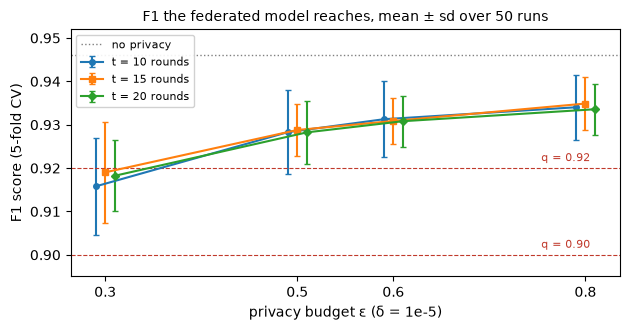

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for t, mk in zip(ROUNDS, "osD"):
    m = [F1[(e, t)].mean() for e in EPSILONS]; s = [F1[(e, t)].std() for e in EPSILONS]
    ax.errorbar(np.array(EPSILONS) + (t - 15) * 0.002, m, yerr=s, marker=mk, ms=4, capsize=2, label=f"t = {t} rounds")
ax.axhline(np.mean([F1[(None, t)].mean() for t in ROUNDS]), color="grey", ls=":", lw=1, label="no privacy")
for q in (0.90, 0.92):
    ax.axhline(q, color="#C0392B", ls="--", lw=0.8)
    ax.text(0.805, q + 0.001, f"q = {q:.2f}", color="#C0392B", fontsize=8, va="bottom", ha="right")
ax.set_xticks(EPSILONS); ax.set_xlabel("privacy budget ε (δ = 1e-5)"); ax.set_ylabel("F1 score (5-fold CV)")
ax.set_title("F1 the federated model reaches, mean ± sd over 50 runs", fontsize=10)
ax.set_ylim(0.895, 0.952); ax.legend(fontsize=8, loc="upper left", framealpha=0.9); fig.tight_layout(); plt.show()

## 5. The domain rule against the data

The rule says that $q \ge 0.92$ is implausible, not impossible, under $\varepsilon \le 0.3$. In the data, that is the share of runs that reach F1 0.92 at $\varepsilon = 0.3$. A rule calibrated on the simulation would take that share as its multiplier $\mu$; since every $\mu$ below $5/6$ yields the same agreement, the negotiation should again reach $\omega^\star = (0.5, 0.92, 10)$.

In [14]:
reach = {e: float(np.mean([np.mean(F1[(e, t)] >= 0.92 - 1e-12) for t in ROUNDS])) for e in EPSILONS}
for e in EPSILONS:
    print(f"eps = {e}: F1 >= 0.92 in {reach[e]:.0%} of runs (all t)")
mu_data = round(reach[0.3], 2)
r = p2a.negotiate_all(p2a.compile_problem(p2a.RUNNING_EXAMPLE, mu=mu_data))
print(f"\nrule calibrated on the data: mu = {mu_data} -> agreements {dict(r['agreements'])} after {r['mean_steps']:.1f} steps on average")

# The share above comes from the same 50 runs that Part 6 uses to score the agreements. Calibrating on 50 fresh seeds
# avoids that circularity; any mu below 5/6 gives the same agreement.
FRESH_SEEDS = range(200, 250)
fresh = np.array(pmap(_eval_one, [(0.3, t, s) for t in ROUNDS for s in FRESH_SEEDS]))
mu_fresh = round(float(np.mean(fresh >= 0.92 - 1e-12)), 2)
r = p2a.negotiate_all(p2a.compile_problem(p2a.RUNNING_EXAMPLE, mu=mu_fresh))
print(f"on fresh seeds 200-249: F1 >= 0.92 in {mu_fresh:.0%} of runs at eps = 0.3 -> mu = {mu_fresh} -> agreements {dict(r['agreements'])}")

eps = 0.3: F1 >= 0.92 in 37% of runs (all t)
eps = 0.5: F1 >= 0.92 in 90% of runs (all t)
eps = 0.6: F1 >= 0.92 in 96% of runs (all t)
eps = 0.8: F1 >= 0.92 in 99% of runs (all t)

rule calibrated on the data: mu = 0.37 -> agreements {(0.5, 0.92, 10): 120} after 17.8 steps on average


on fresh seeds 200-249: F1 >= 0.92 in 42% of runs at eps = 0.3 -> mu = 0.42 -> agreements {(0.5, 0.92, 10): 120}


## 6. Executing the agreements

Executing an agreement means training under its $\varepsilon$ and $t$ and checking whether the model reaches its F1 target $q$. Every agreement of Table 1 is trained on the same 50 seeds as above.

In [15]:
def execute(omega):
    eps, q, t = omega
    f = np.array([run_cv(eps, t, s, **TUNED[(eps, t)]) for s in EVAL_SEEDS])
    assert np.allclose(f, F1[(eps, t)])          # same seeds, same runs as the map above
    return f

done = {}
for label in nego:
    for omega in nego[label]["dist"]:
        if omega not in done:
            done[omega] = execute(omega)
table = table_nego.copy()
table["F1 mean"] = [round(done[o].mean(), 3) for o in table._omega]
table["target met"] = [f"{np.mean(done[o] >= o[1] - 1e-12):.0%}" for o in table._omega]

def wilson(k, n, z=1.96):                       # 95% Wilson interval for a share of k successes in n runs
    p, d = k / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

table["95% interval"] = [("{:.0%} to {:.0%}".format(*wilson(int(np.sum(done[o] >= o[1] - 1e-12)), len(done[o])))) for o in table._omega]
table = table.drop(columns="_omega")
table

,setting,omega_f,agreement,runs,u_H1,u_H2,u_R,steps,F1 mean,target met,95% interval
0,no domain rule,48,"(0.3, 0.92, 10)",120/120,1.00,1.00,1.00,2.3,0.916,32%,21% to 46%
1,"rule, mu = 0.2",48,"(0.5, 0.92, 10)",120/120,0.83,0.83,1.00,17.8,0.928,88%,76% to 94%
2,"rule, mu = 0.5",48,"(0.5, 0.92, 10)",120/120,0.83,0.83,1.00,17.8,0.928,88%,76% to 94%
3,"rule, mu = 0.8",48,"(0.5, 0.92, 10)",120/120,0.83,0.83,1.00,17.8,0.928,88%,76% to 94%
4,"rule, mu = 0.9",48,"(0.3, 0.92, 10)",120/120,0.90,1.00,1.00,2.3,0.916,32%,21% to 46%
5,+ consortium's t >= 15,32,"(0.3, 0.9, 15)",60/120,0.83,0.75,0.58,18.3,0.919,92%,81% to 97%
6,+ consortium's t >= 15,32,"(0.5, 0.92, 15)",60/120,0.83,0.58,0.75,18.3,0.929,92%,81% to 97%
7,+ H1: privacy first,32,"(0.3, 0.9, 15)",120/120,0.83,0.75,0.58,20.3,0.919,92%,81% to 97%
8,"variant, no rule",48,"(0.3, 0.92, 15)",120/120,1.00,0.75,0.75,34.1,0.919,40%,28% to 54%
9,"variant, mu = 0.2",48,"(0.5, 0.92, 15)",120/120,0.83,0.58,0.75,57.2,0.929,92%,81% to 97%


In [16]:
out = {
    "data": "Wisconsin breast cancer (original), OpenML 15 (data/breast_w.csv): 699 patients, 9 features on a public 1..10 scale",
    "federation": "5-fold CV; training folds split, stratified, between H1 and H2; R averages (FedAvg)",
    "privacy": {"delta": DELTA, "accountant": "RDP of the Poisson-subsampled Gaussian, integer orders 2..512, "
                "conversion of Canonne, Kamath and Steinke (2020)"},
    "model": "logistic regression, DP-SGD (per-example clipping C, noise sigma*C), one local epoch per round, l2 = 1e-3",
    "tuning": {"grid": GRID, "tune_seeds": list(TUNE_SEEDS), "eval_seeds": list(EVAL_SEEDS),
               "tuned": {f"{e}|{t}": h for (e, t), h in TUNED.items()}},
    "attainability": {f"{e}|{t}": {"mean": float(f.mean()), "sd": float(f.std()), "f1_runs": f.round(4).tolist(),
                                   "p_reach": {f"{q:.2f}": float(np.mean(f >= q - 1e-12)) for q in Q}}
                      for (e, t), f in F1.items()},
    "share_reaching_092": reach, "mu_data": mu_data, "mu_fresh_seeds_200_249": mu_fresh,
    "table1_executed": table.to_dict(orient="records"),
}
(RESULTS / "fl_dp_results.json").write_text(json.dumps(out, indent=1))
print(f"wrote results/fl_dp_results.json; total {time.time() - T0:.0f} s")

wrote results/fl_dp_results.json; total 60 s


## 7. The language-model rule proposals (recorded)

Section 4 reports that a language-model agent, given only the structured constraints, flagged the same pair of $H_1$ with $\mu = 0.5$ and matched the hand-written rules on 12 of the 13 agents with a valid answer. Those calls need an API key and a model that changes over time, so they are not re-run here; `results/llm_rule_proposals.csv` holds the recorded answers (Gemini Flash, API alias `gemini-flash-latest`) for the parties of the prototype's five test scenarios.

In [17]:
llm = pd.read_csv(RESULTS / "llm_rule_proposals.csv", dtype=str).fillna("")
valid = llm[llm.llm_valid == "True"]
print(f"{len(valid)} of {len(llm)} parties got a valid answer; it matched the hand-written rule for "
      f"{(valid.agree_on_which_constraints == 'True').sum()} of {len(valid)}")
llm[["scenario", "agent", "hand_authored_flagged", "llm_flagged", "llm_multiplier", "agree_on_which_constraints"]]

13 of 14 parties got a valid answer; it matched the hand-written rule for 12 of 13


,scenario,agent,hand_authored_flagged,llm_flagged,llm_multiplier,agree_on_which_constraints
0,scenario_1_original,H1,H1_c_eps;H1_c_q,H1_c_eps;H1_c_q,0.5,True
1,scenario_1_original,H2,,,1.0,True
2,scenario_1_original,R,,,1.0,True
3,scenario_2_bilateral,P,P_c_eps;P_c_q,P_c_eps;P_c_q,0.8,True
4,scenario_2_bilateral,Q,,,1.0,True
5,scenario_3_no_conflict,X,,,1.0,True
6,scenario_3_no_conflict,Y,,,1.0,True
7,scenario_3_no_conflict,Z,,,1.0,True
8,scenario_4_four_agents,A,A_c_eps;A_c_q,,1.0,False
9,scenario_4_four_agents,B,,,1.0,True


## 8. What this shows, and what it does not

* The agreement policies of Table 1 can be executed: every agreed configuration is a federated training whose privacy cost the accountant fixes at the agreed $\varepsilon$, and whose F1 score can be checked against the agreed target.
* The domain rule is borne out by the simulation: under $\varepsilon = 0.3$, F1 0.92 is reached only in a minority of runs (implausible, not impossible), whereas the agreements reached with the rule meet their targets in most runs. Without the rule, the parties agree on a configuration that usually fails its own target.
* This is a simulation on one small public dataset, with a logistic regression, two IID hospitals and hyperparameters tuned offline. NumPy's generator is not a cryptographic source, so the code simulates the DP guarantee rather than providing it. The check grounds the rule in data; it does not replace validation by domain experts (challenge C1 of the paper).